
0: 640x640 4 persons, 1 bottle, 2 tvs, 4.9ms
Speed: 0.0ms preprocess, 4.9ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 persons, 1 backpack, 3.9ms
Speed: 0.0ms preprocess, 3.9ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 persons, 4.2ms
Speed: 0.0ms preprocess, 4.2ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


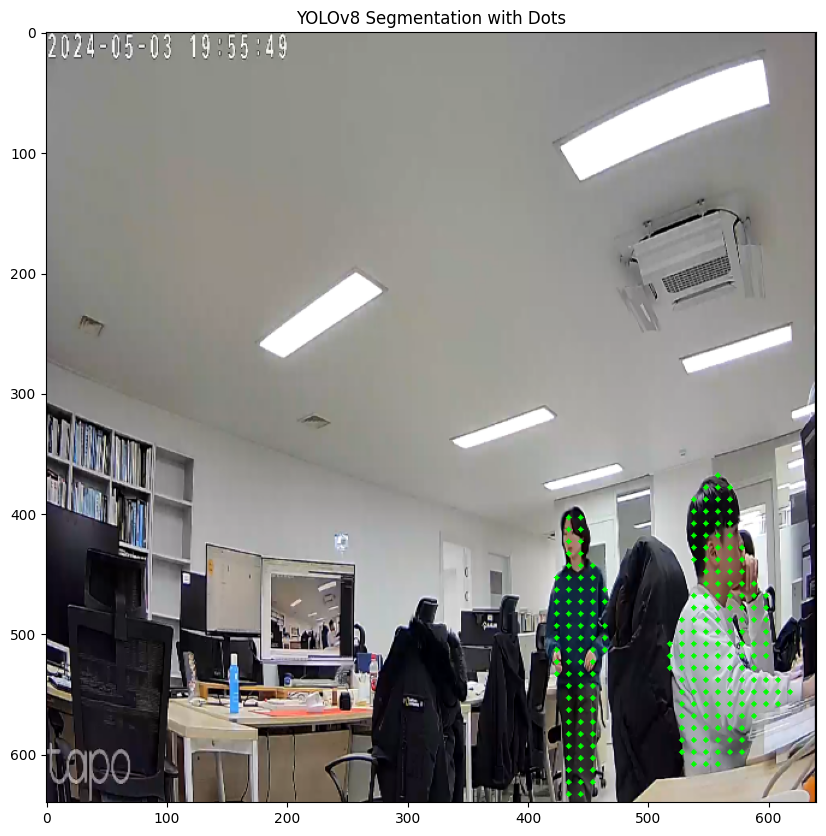

In [155]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import torch

# YOLOv8 모델 로드
box_model = YOLO("yolov8n.pt")
seg_model = YOLO("yolov8n-seg.pt")

# 모델을 CUDA로 이동
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
box_model.to(device)
seg_model.to(device)

# 이미지 읽기
image_path = "../data/test.png"
image = cv2.imread(image_path)

# 점 간격 설정
dot_spacing = 10

# OpenCV BGR -> RGB로 변환
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# 원본 이미지 크기 저장 (나중에 좌표 보정에 사용)
original_height, original_width = image.shape[:2]

# 이미지 640x640으로 리사이즈(YOLO 모델이 32 배수로 된 이미지가 아니면 처리를 못함)
image_resized = cv2.resize(image_rgb, (640, 640))

# 이미지를 torch tensor로 변환하고 CUDA 장치로 이동
image_tensor = torch.from_numpy(image_resized).permute(2, 0, 1).unsqueeze(0).float().to(device) / 255.0

# 이미지에서 객체 탐지
results = box_model(image_tensor)

# 탐지 결과 처리
for result in results[0].boxes:
    box = result.xyxy[0].cpu().numpy()  # (x1, y1, x2, y2)
    cls = int(result.cls)  # 클래스 ID
    conf = result.conf.item()  # 신뢰도
    label = box_model.names[cls]  # 클래스 이름

    if label == "person" and conf >= 0.8:  # 사람 클래스만 필터링
        x1, y1, x2, y2 = map(int, box)

        # 여백 크기 설정(여백 설정 안하면 세그가 탐지를 잘 못함)
        padding = 10
        
        x1 = max(0, x1 - padding)  # 왼쪽 여백
        x2 = min(image_resized.shape[1], x2 + padding)  # 오른쪽 여백
        
        y1 = max(0, y1 - padding)  # 위쪽 여백
        y2 = min(image_resized.shape[0], y2 + padding)  # 아래쪽 여백

        # 바운딩 박스 내 이미지 잘라내기
        cropped_image = image_resized[y1:y2, x1:x2]
        cropped_resized = cv2.resize(cropped_image, (640, 640))

        # 세그멘테이션 모델 실행
        cropped_tensor = (
            torch.from_numpy(cropped_resized).permute(2, 0, 1).unsqueeze(0).float().to(device) / 255.0
        )
        seg_results = seg_model(cropped_tensor)
        
        # 세그멘테이션 마스크 확인
        if seg_results[0].masks is not None:  # 마스크가 유효한 경우에만 진행
            mask = seg_results[0].masks.data[0].cpu().numpy()  # 첫 번째 결과의 마스크
            mask_resized = cv2.resize(mask, (x2 - x1, y2 - y1))  # 원래 바운딩 박스 크기로 리사이즈
        
            # 마스크가 있는 영역에만 점 그리기
            for y in range(y1, y2, dot_spacing):  # Y축 방향 점 배치
                for x in range(x1, x2, dot_spacing):  # X축 방향 점 배치
                    # 마스크 내부 여부 확인
                    mask_x = x - x1
                    mask_y = y - y1
                    if mask_resized[mask_y, mask_x] > 0.5:  # 마스크 영역 안인지 확인
                        cv2.circle(image_resized, (x, y), 2, (0, 255, 0), -1)
        else:
            print(f"No valid mask found for box {box}")



plt.figure(figsize=(10, 10))
plt.imshow(image_resized)
# plt.axis("off")
plt.title("YOLOv8 Segmentation with Dots")
plt.show()

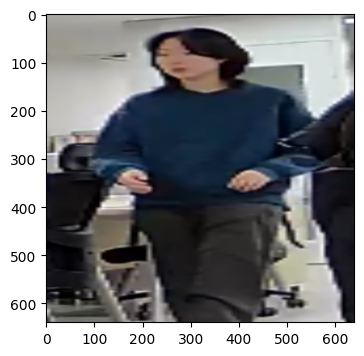

In [150]:
plt.figure(figsize=(4, 4))
plt.imshow(cropped_resized)

In [143]:
image_resized.shape[1]

640